# AI Customer Intelligence — Análise Exploratória de Feedbacks

## Objetivo

Este notebook realiza a análise exploratória dos feedbacks processados pelo sistema AI Customer Intelligence.

Os feedbacks foram previamente classificados por uma LLM em diferentes dimensões, incluindo:

- Categoria
- Assunto
- Sentimento
- Urgência
- Resumo
- Possível causa
- Ação recomendada

O objetivo desta análise é transformar essas classificações em informações úteis para identificação de problemas recorrentes, avaliação da experiência dos clientes e priorização de ações.

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("/content/feedback_enriched.csv")

df.head()

,id,feedback,categoria,assunto,sentimento,urgencia,resumo,possivel_causa,acao_recomendada,status,erro
0,1,"Não consigo fazer pix, aparece erro toda vez q...",pix,erro_ao_realizar_pix,negativo,alta,Não consigo realizar PIX; aparece erro ao conf...,Causa específica não pode ser determinada com ...,Atualize e reinicie o aplicativo; se o erro pe...,sucesso,NaN
1,2,Queria saber onde altero meus dados pessoais n...,aplicativo,duvida_aplicativo,neutro,baixa,Usuário pergunta onde alterar seus dados pesso...,Usuário não localizou a opção de editar dados ...,Informar o caminho no app (por exemplo: Perfil...,sucesso,NaN
2,3,Meu histórico mostra dois pagamentos idênticos...,boleto,pagamento_duplicado,neutro,alta,Foram realizados dois pagamentos idênticos do ...,Processamento duplicado do pagamento (erro do ...,"Contactar o atendimento do banco, anexar compr...",sucesso,NaN
3,4,O valor da parcela do meu empréstimo veio maio...,emprestimo,parcela_incorreta,negativo,media,A parcela do empréstimo veio com valor maior n...,Não é possível determinar a causa específica s...,Verifique o extrato e o contrato e contate o a...,sucesso,NaN
4,5,Gostaria de revisar uma cobrança porque o valo...,boleto,cobranca_incorreta,neutro,media,Valor do boleto não corresponde ao contrato.,Provável erro na emissão do boleto ou divergên...,"Solicitar revisão da cobrança, confrontar com ...",sucesso,NaN


In [4]:
df.shape

(120, 11)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 120 entries, 0 to 119
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   id                120 non-null    int64  
 1   feedback          120 non-null    object 
 2   categoria         120 non-null    object 
 3   assunto           120 non-null    object 
 4   sentimento        120 non-null    object 
 5   urgencia          120 non-null    object 
 6   resumo            120 non-null    object 
 7   possivel_causa    120 non-null    object 
 8   acao_recomendada  120 non-null    object 
 9   status            120 non-null    object 
 10  erro              0 non-null      float64
dtypes: float64(1), int64(1), object(9)
memory usage: 10.4+ KB


In [6]:
df.columns

Index(['id', 'feedback', 'categoria', 'assunto', 'sentimento', 'urgencia',
       'resumo', 'possivel_causa', 'acao_recomendada', 'status', 'erro'],
      dtype='object')

In [7]:
df.isnull().sum()

,0
id,0
feedback,0
categoria,0
assunto,0
sentimento,0
urgencia,0
resumo,0
possivel_causa,0
acao_recomendada,0
status,0


In [8]:
df["status"].value_counts()

,count
status,
sucesso,120


## 1. Distribuição dos feedbacks por categoria

A primeira análise busca identificar quais áreas concentram o maior volume de feedbacks no conjunto analisado.

In [9]:
cont_categoria = df["categoria"].value_counts()
cont_categoria

,count
categoria,
pix,35
cartao_credito,30
aplicativo,21
boleto,14
emprestimo,10
atendimento,10


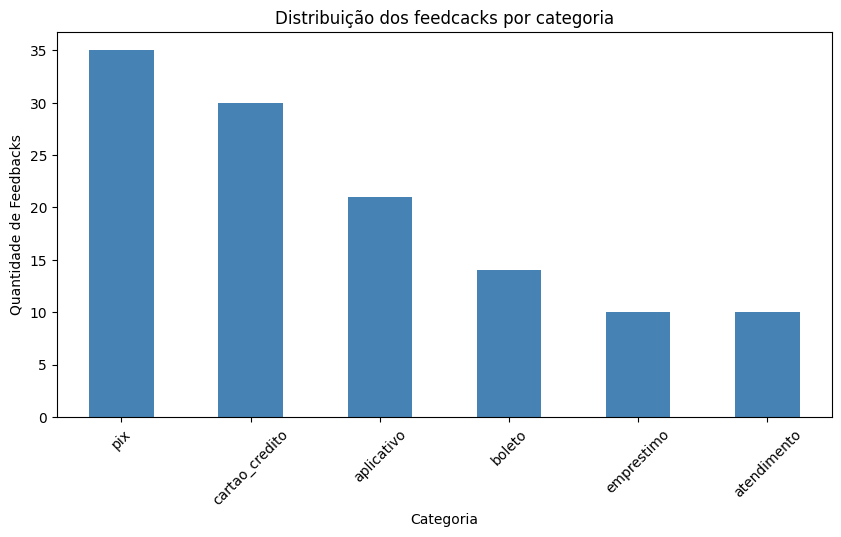

In [47]:
plt.figure(figsize=(10, 5))
ax = cont_categoria.plot(kind="bar", color="steelblue")

plt.title("Distribuição dos feedcacks por categoria")
plt.xlabel("Categoria")
plt.ylabel("Quantidade de Feedbacks")
plt.xticks(rotation=45)
plt.show()

for container in ax.containers:
    ax.bar_label(container)

plt.show()

## 2. Assuntos mais frequentes

Além das categorias gerais, os assuntos permitem identificar de forma mais específica os tipos de solicitações e problemas representados no conjunto de feedbacks.

In [11]:
cont_assuntos = df["assunto"].value_counts()
cont_assuntos

,count
assunto,
pix_nao_recebido,9
pix_em_processamento,7
compra_nao_reconhecida,7
erro_ao_realizar_pix,6
compra_recusada,6
problema_login,6
erro_aplicativo,6
problema_chave_pix,5
problema_fatura,5


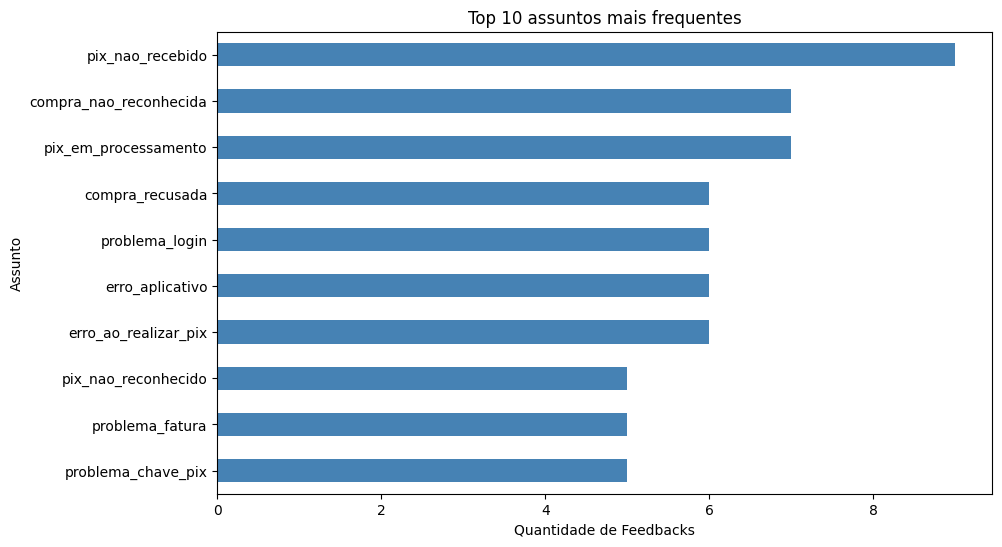

In [35]:
top_assuntos = cont_assuntos.head(10)

plt.figure(figsize=(10, 6))
top_assuntos.sort_values().plot(kind="barh", color="steelblue")

plt.title("Top 10 assuntos mais frequentes")
plt.xlabel("Quantidade de Feedbacks")
plt.ylabel("Assunto")

for container in ax.containers:
  ax.bar_label(container)

plt.show()

## 3. Análise de sentimento

A análise de sentimento busca identificar como os clientes se expressam nos feedbacks, distinguindo diferentes níveis de satisfação e insatisfação.

Diferentemente das categorias e assuntos utilizados na geração do dataset, o sentimento foi inferido pela LLM a partir do conteúdo textual de cada feedback.

In [13]:
cont_sentimento = df["sentimento"].value_counts()
cont_sentimento

,count
sentimento,
negativo,92
neutro,25
muito_negativo,2
muito_positivo,1


In [42]:
ordem_sentimento = ["muito_negativo","negativo","neutro","positivo","muito_positivo"]

cont_sentimento = (df['sentimento'].value_counts().reindex(ordem_sentimento, fill_value=0))
cont_sentimento


,count
sentimento,
muito_negativo,2
negativo,92
neutro,25
positivo,0
muito_positivo,1


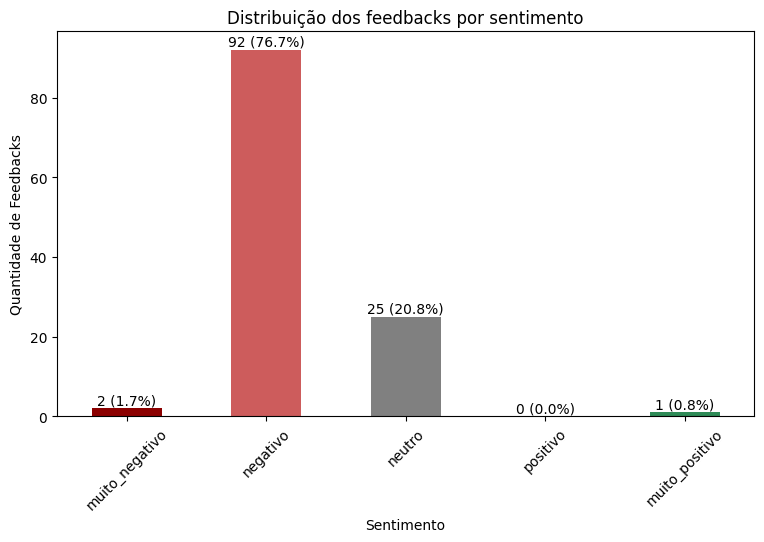

In [45]:
cores = {"muito_negativo":"darkred", "negativo":"indianred","neutro": "gray","positivo": "lightgreen","muito_positivo": "seagreen"}

plt.figure(figsize=(9, 5))
ax = cont_sentimento.plot(kind="bar", color=[cores[x] for x in cont_sentimento.index])

plt.title("Distribuição dos feedbacks por sentimento")
plt.xlabel("Sentimento")
plt.ylabel("Quantidade de Feedbacks")
plt.xticks(rotation=45)

total = cont_sentimento.sum()

for i, v in enumerate(cont_sentimento):
  porcentagem = v/total *100

  ax.text(i, v+1, f"{v} ({porcentagem:.1f}%)", ha="center")

plt.show()

## 4. Análise de urgência

A urgência representa a prioridade operacional atribuída pela LLM a cada feedback, considerando o impacto do problema relatado sobre o cliente.

In [38]:


cont_urgencia = df["urgencia"].value_counts()
cont_urgencia
ordem_urgencia = ["baixa", "media", "alta", "critica"]
cont_urgencia = (df["urgencia"].value_counts().reindex(ordem_urgencia, fill_value=0))

cont_urgencia

,count
urgencia,
baixa,6
media,39
alta,45
critica,30


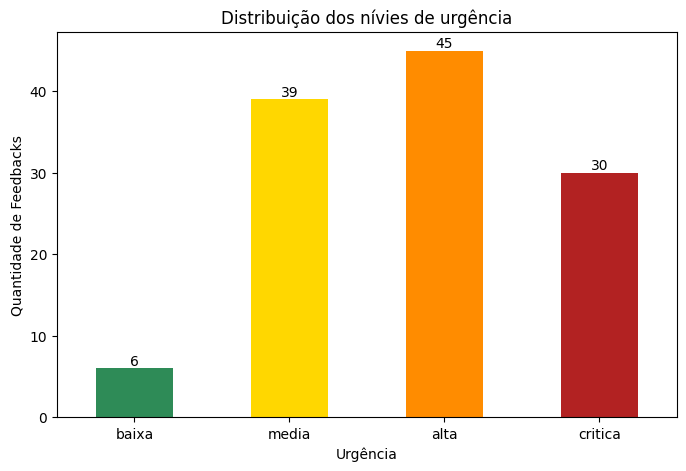

In [46]:
cores_urgencia = {"baixa":"seagreen","media": "gold","alta": "darkorange","critica": "firebrick"}

plt.figure(figsize=(8, 5))
ax = cont_urgencia.plot(kind="bar", color=[cores_urgencia[x] for x in cont_urgencia.index])

plt.title("Distribuição dos nívies de urgência")
plt.xlabel("Urgência")
plt.ylabel("Quantidade de Feedbacks")
plt.xticks(rotation=0)

for container in ax.containers:
  ax.bar_label(container)
plt.show()

In [23]:
casos_prioritarios = df[df["urgencia"].isin(["alta", "critica"])]
len(casos_prioritarios)

75

In [24]:
percentual_prioritarios = (len(casos_prioritarios)/ len(df)*100)
print(f"{percentual_prioritarios:.2f}% dos feedbacks são de urgência alta ou crítica")

62.50% dos feedbacks são de urgência alta ou crítica


## 5. Urgência por categoria

A análise conjunta de categoria e urgência permite identificar em quais áreas estão concentrados os feedbacks que exigem maior prioridade de tratamento.

In [25]:
categoria_urgencia = pd.crosstab(df["categoria"], df["urgencia"])
categoria_urgencia

urgencia,alta,baixa,critica,media
categoria,,,,
aplicativo,6,2,6,7
atendimento,0,2,0,8
boleto,3,1,4,6
cartao_credito,12,0,10,8
emprestimo,5,1,2,2
pix,19,0,8,8


In [27]:
categoria_urgencia = categoria_urgencia.reindex(columns=ordem_urgencia, fill_value=0)
categoria_urgencia

urgencia,baixa,media,alta,critica
categoria,,,,
aplicativo,2,7,6,6
atendimento,2,8,0,0
boleto,1,6,3,4
cartao_credito,0,8,12,10
emprestimo,1,2,5,2
pix,0,8,19,8


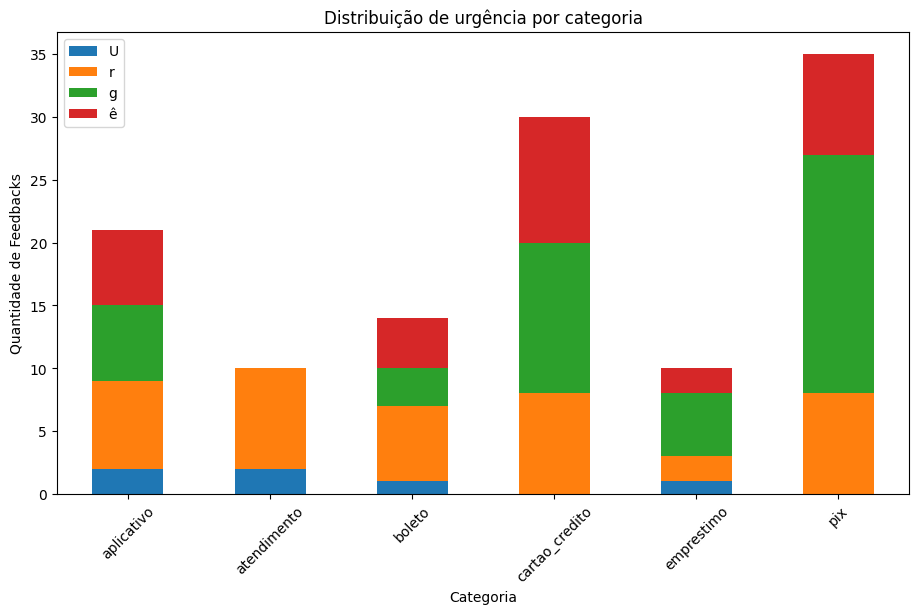

In [28]:
categoria_urgencia.plot(kind="bar", stacked=True, figsize=(11,6))

plt.title("Distribuição de urgência por categoria")
plt.xlabel("Categoria")
plt.ylabel("Quantidade de Feedbacks")
plt.xticks(rotation=45)
plt.legend("Urgência")
plt.show()

## 6. Sentimento por categoria

Este cruzamento permite observar como os diferentes níveis de sentimento estão distribuídos entre as categorias analisadas.

In [29]:
categoria_sentimento = pd.crosstab(df["categoria"], df["sentimento"])
categoria_sentimento = categoria_sentimento.reindex(columns=ordem_sentimento, fill_value=0)
categoria_sentimento

sentimento,muito_negativo,negativo,neutro,positivo,muito_positivo
categoria,,,,,
aplicativo,0,17,4,0,0
atendimento,1,8,0,0,1
boleto,0,11,3,0,0
cartao_credito,0,26,4,0,0
emprestimo,0,8,2,0,0
pix,1,22,12,0,0


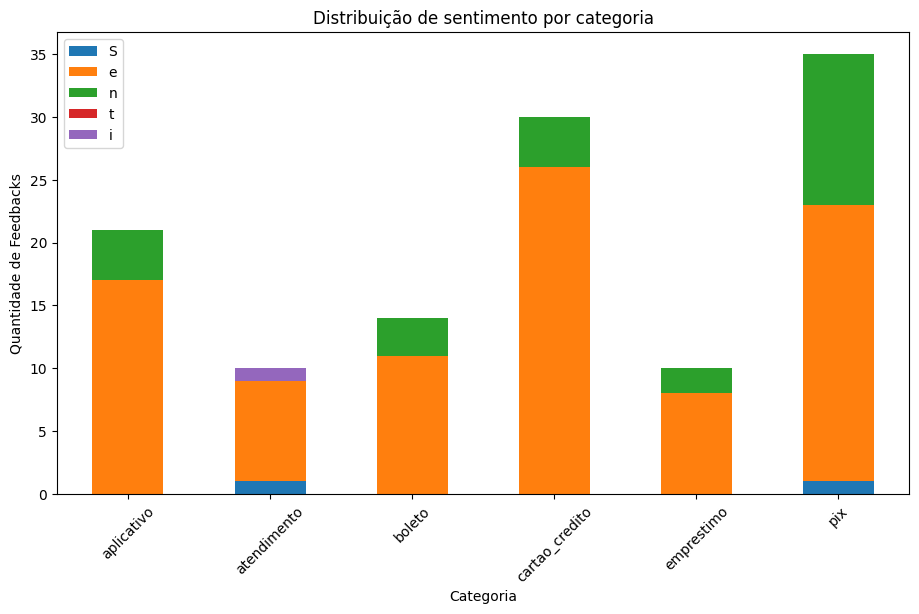

In [30]:
categoria_sentimento.plot(kind="bar", stacked=True, figsize=(11,6))

plt.title("Distribuição de sentimento por categoria")
plt.xlabel("Categoria")
plt.ylabel("Quantidade de Feedbacks")
plt.xticks(rotation=45)
plt.legend("Sentimento")
plt.show()

## 7. Principais Insights e Conclusões

A partir das análises realizadas, podemos perceber que a maior parte dos feedbacks foi classificada como negativa, representando cerca de **76,7% dos dados**. Isso faz sentido levando em consideração que o dataset foi criado principalmente com situações envolvendo problemas, reclamações e dificuldades enfrentadas pelos clientes.

Também foi possível perceber a diferença entre **sentimento e urgência**. Um cliente pode estar insatisfeito com alguma situação e demonstrar um sentimento negativo, mas isso não significa necessariamente que o problema seja urgente. A urgência está mais relacionada ao impacto do problema e à prioridade que ele deveria receber.

Os cruzamentos entre categoria, sentimento e urgência também ajudam a mostrar como esses dados poderiam ser utilizados na prática. Em um cenário real, seria possível identificar quais tipos de problemas estão gerando mais insatisfação e, ao mesmo tempo, quais deles precisam ser tratados com maior prioridade.

É importante lembrar que a quantidade de feedbacks de cada categoria não representa a frequência real desses problemas. Como o dataset é sintético, nós mesmos definimos durante sua criação quantos exemplos aproximadamente existiriam de Pix, cartão de crédito, aplicativo, boleto, atendimento e empréstimo. Por isso, não podemos concluir, por exemplo, que problemas relacionados a Pix são realmente mais frequentes apenas porque aparecem mais vezes neste dataset.

No geral, o projeto mostra como feedbacks escritos em linguagem natural podem ser transformados em informações estruturadas utilizando uma LLM. A partir de um texto simples enviado por um cliente, conseguimos obter categoria, assunto, sentimento, urgência, resumo, possível causa e ação recomendada. Depois, essas informações podem ser organizadas e analisadas para facilitar a identificação de problemas e ajudar na tomada de decisões.